# Single-compartment neurons: `Cell.point` and the one-CV cable `Cell`

A point neuron is written directly as `Cell.point(N, length=..., radius=...)`. It is shorthand for `Cell(Morphology.from_soma(...), cv_policy=Lumped())`: it is declared the same way as a morphological `Cell` (`paint`, `place`, `record`, `run`), but at run time it has no CV axis, `V` has shape `(N,)`, and the default solver is `ralston2`. braincell 0.3 removed the earlier point-neuron classes; for a line-by-line rewrite of models written with them, see the migration table in the cells concept guide.

A lumped `Cell` is used like a morphological `Cell`: View reads and writes, trainable parameters, point synapses, recording, and as a `Network` population (both a spike source and a synapse target). Its results match a one-CV cable `Cell` declared the same way (the comparison target of CELL-24), only without that CV axis of length 1. A cable `Cell(pop_size=(N,))` with a single CV is still available: it keeps three electrical points, proximal, midpoint and distal, and `V` has shape `(N, 1)`.

| Aspect | `Cell.point` (lumped) | One-CV cable `Cell` |
|---|---|---|
| Voltage shape | `(N,)` | `(N, 1)` |
| Electrical points | 1 (CV midpoint) | 3 (proximal, midpoint, distal) |
| Current input | clamp (omit the locset for the only site), `update(I_ext)` (current or density), brainpy projections | clamp or input binding |
| Default solver | `ralston2` | `staggered` |
| Channel configuration, point synapses, `Network`, View, trainable parameters, `record()` | same | same |
| Spatial extension | switch to a morphology | add more branches and CVs |


In [1]:
import time

import brainstate
import brainunit as u
import jax
import matplotlib.pyplot as plt
import numpy as np

import braincell
from braincell.filter import AllRegion, RootLocation, at

plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP"]
plt.rcParams["axes.unicode_minus"] = False

DT = 0.025 * u.ms
SOMA_LENGTH = 20.0 * u.um
SOMA_RADIUS = 10.0 * u.um
SOMA_AREA = 2.0 * u.math.pi * SOMA_RADIUS * SOMA_LENGTH
CURRENT_DENSITY = 10.0 * u.uA / u.cm**2
TOTAL_CURRENT = (CURRENT_DENSITY * SOMA_AREA).in_unit(u.nA)

print(f"backend={jax.default_backend()}, x64={jax.config.jax_enable_x64}")
print(f"membrane area={SOMA_AREA.in_unit(u.um**2)}, equivalent total current={TOTAL_CURRENT}")

backend=cpu, x64=False
membrane area=1256.6371 um^2, equivalent total current=0.12566371 nA


In [2]:
def make_soma():
    soma = braincell.Branch.from_lengths(
        lengths=[20.0] * u.um,
        radii=[10.0, 10.0] * u.um,
        type="soma",
    )
    return braincell.Morphology.from_root(soma, name="soma")


def channel_mechanisms(active):
    mechanisms = [
        braincell.mech.CableProperty(
            resting_potential=-54.3 * u.mV,
            membrane_capacitance=1.0 * u.uF / u.cm**2,
            axial_resistivity=100.0 * u.ohm * u.cm,
        ),
        braincell.mech.Channel("IL", name="leak", g_max=0.3 * u.mS / u.cm**2, E=-54.3 * u.mV),
    ]
    if active:
        mechanisms += [
            braincell.mech.Ion("SodiumFixed", E=50.0 * u.mV),
            braincell.mech.Ion("PotassiumFixed", E=-77.0 * u.mV),
            braincell.mech.Channel("Na_HH1952", name="na", g_max=120.0 * u.mS / u.cm**2),
            braincell.mech.Channel("K_HH1952", name="k", g_max=36.0 * u.mS / u.cm**2),
        ]
    return mechanisms


def build_point_cell(size, *, active, solver="rk4", clamp=None, synapse=False):
    """A lumped (point) Cell: V has shape (size,)."""
    cell = braincell.Cell.point(
        size,
        length=SOMA_LENGTH,
        radius=SOMA_RADIUS,
        V_init=-65.0 * u.mV,
        V_th=0.0 * u.mV,
        solver=solver,
    )
    cell.paint(AllRegion(), *channel_mechanisms(active))
    if clamp is not None:
        cell.place(clamp)  # the only site: the CV midpoint
    if synapse:
        cell.place(braincell.mech.Synapse("ExpSyn", name="ampa", tau=2.0 * u.ms, e=0.0 * u.mV))
    cell.record("v", braincell.observe.state("V"))
    return cell


def build_one_cv_cell(size, *, active, solver="rk4", clamp=None, synapse=False):
    cell = braincell.Cell(
        make_soma(),
        pop_size=(size,),
        cv_policy=braincell.CVPerBranch(),
        V_init=-65.0 * u.mV,
        V_th=0.0 * u.mV,
        solver=solver,
    )
    cell.paint(AllRegion(), *channel_mechanisms(active))
    if clamp is not None:
        cell.place(RootLocation(0.5), clamp)
    if synapse:
        cell.place(
            at("soma", 0.5),
            braincell.mech.Synapse("ExpSyn", name="ampa", tau=2.0 * u.ms, e=0.0 * u.mV),
        )
    cell.record("v", braincell.observe.state("V"))
    return cell

## Numerical equivalence

The two `Cell`s below use the same cylinder area, membrane capacitance, reversal potentials, maximal conductances, initial values and RK4; the clamp injects the total current converted from a current density and the membrane area, and the HH gates start at steady state after initialization. `Cell.point` solves the point-neuron equation and the one-CV cable `Cell` solves the three-point cable equation: the passive model gives the same voltage, and the HH model differs only at the level of float32 rounding.


Voltage shape: (4,) (Cell.point) (4, 1) (one-CV cable Cell)


Passive: max difference between the one-CV cable Cell and Cell.point 0 mV
HH: max difference between the one-CV cable Cell and Cell.point 3.8147e-06 mV
Spike time (ms): [1.9] (Cell.point) -> [1.9] (one-CV cable Cell)


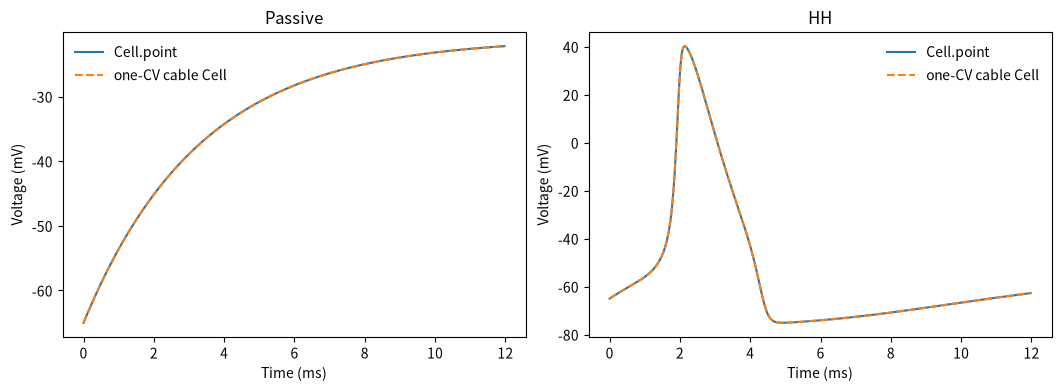

In [3]:
def run_cell(cell, duration):
    result = cell.run(dt=DT, duration=duration)
    return (
        np.asarray(result.samples["v"].time.to_decimal(u.ms)),
        np.asarray(result.samples["v"].values.to_decimal(u.mV)),
    )


def upward_crossings(times, voltage, threshold=0.0):
    voltage = np.asarray(voltage).reshape(-1)
    rows = np.flatnonzero((voltage[:-1] < threshold) & (voltage[1:] >= threshold)) + 1
    return np.asarray(times)[rows]


shape_point = build_point_cell(4, active=False)
shape_point.init_state()
shape_cell = build_one_cv_cell(4, active=False)
shape_cell.init_state()
print("Voltage shape:", shape_point.V.value.shape, "(Cell.point)", shape_cell.V.value.shape, "(one-CV cable Cell)")

DURATION = 12.0 * u.ms
comparisons = {}
for label, active in (("Passive", False), ("HH", True)):
    clamp = braincell.mech.CurrentClamp(durations=DURATION, amplitudes=TOTAL_CURRENT)
    point_t, point_v = run_cell(build_point_cell(1, active=active, clamp=clamp), DURATION)
    cell_t, cell_v = run_cell(build_one_cv_cell(1, active=active, clamp=clamp), DURATION)
    comparisons[label] = point_t, point_v[:, 0], cell_t, cell_v[:, 0]

for label, (point_t, point_v, cell_t, cell_v) in comparisons.items():
    print(f"{label}: max difference between the one-CV cable Cell and Cell.point {np.max(np.abs(cell_v - point_v)):.6g} mV")
point_t, point_v, cell_t, cell_v = comparisons["HH"]
print("Spike time (ms):", upward_crossings(point_t, point_v), "(Cell.point) ->",
      upward_crossings(cell_t, cell_v), "(one-CV cable Cell)")

figure, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
for axis, (label, values) in zip(axes, comparisons.items()):
    point_t, point_v, cell_t, cell_v = values
    axis.plot(point_t, point_v, label="Cell.point")
    axis.plot(cell_t, cell_v, "--", label="one-CV cable Cell")
    axis.set(title=label, xlabel="Time (ms)", ylabel="Voltage (mV)")
    axis.legend(frameon=False)
plt.show()


## A network of lumped Cells

A lumped `Cell` can join a `Network` directly: `event_outputs["spike"]` serves as the spike source and `synapses["ampa"]` as the synapse target.

Below, pre and post are both three-member lumped HH populations. Three clamp amplitudes produce different firing times, which drive post through a one-to-one `ExpSyn` connection. The same network is built once more from one-CV cable `Cell`s (also `rk4`) for comparison: both give the same spike events, and the voltages differ only by floating-point rounding.

Network(name='lumped', populations=2, connections=1, rows=3)
  populations:
    pre: size=3, kind=cell, model=Cell, initialized=True
    post: size=3, kind=cell, model=Cell, initialized=True
  connections:
    post: connections=1, rows=3
      drive: CellSpikeSource(Cell.spike) -> ExpSyn(ampa), rows=3
Recorded shapes: (800, 3) (800, 3)
Event counts: 3 3
pre: spike events match the one-CV cable Cell = True; max voltage difference 0.000124 mV
post: spike events match the one-CV cable Cell = True; max voltage difference 7.63e-06 mV


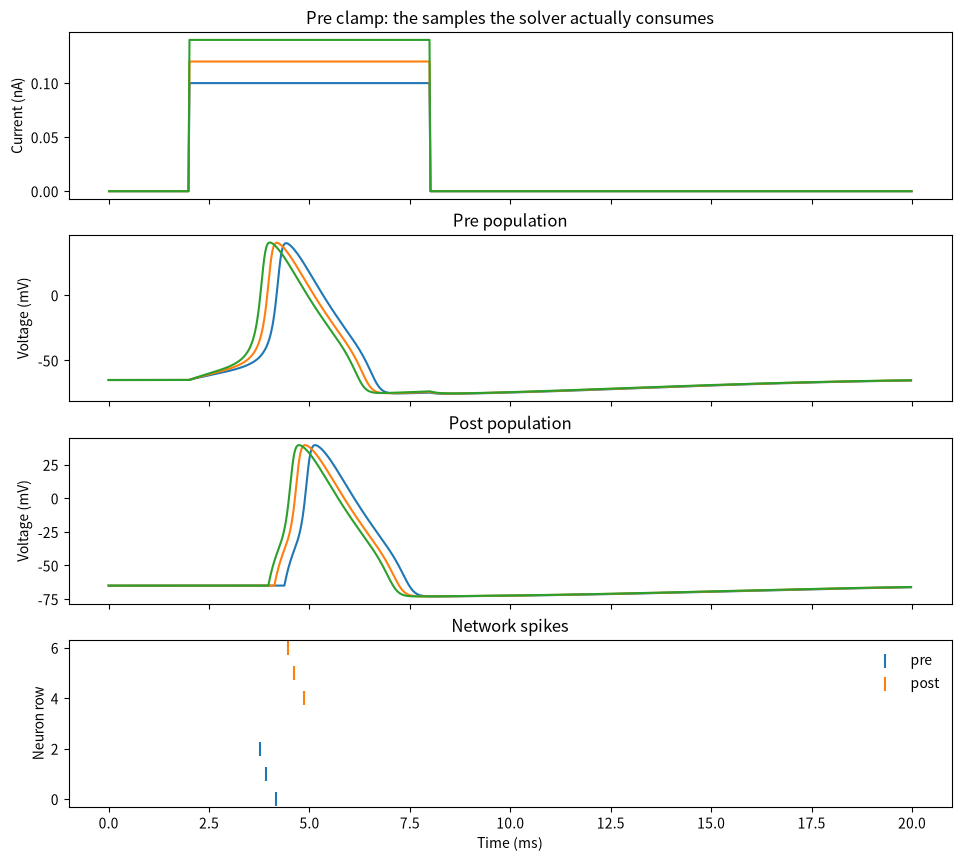

In [4]:
def drive_network(build, name):
    pre_clamp = braincell.mech.CurrentClamp(
        delay=2.0 * u.ms,
        durations=6.0 * u.ms,
        amplitudes=np.asarray([0.10, 0.12, 0.14]) * u.nA,
    )
    pre_cell = build(3, active=True, clamp=pre_clamp)
    post_cell = build(3, active=True, synapse=True)
    pre_cell.clamps.record("input")
    network = braincell.Network(name)
    pre = network.add_population("pre", pre_cell)
    post = network.add_population("post", post_cell)
    network.connect(
        "drive",
        source=pre.event_outputs["spike"],
        synapse=post.synapses["ampa"],
        weight=0.03 * u.uS,
        delay=0.2 * u.ms,
    )
    return network, pre, network.run(dt=DT, duration=20.0 * u.ms)


network, pre, network_result = drive_network(build_point_cell, "lumped")
_, _, twin_result = drive_network(build_one_cv_cell, "one_cv_twin")

pre_v = network_result.samples["pre"]["v"]
post_v = network_result.samples["post"]["v"]
input_block = network_result.samples["pre"]["input"]
pre_events = network_result.events["pre"]["spike"]
post_events = network_result.events["post"]["spike"]

print(network)
print("Recorded shapes:", pre_v.values.shape, post_v.values.shape)
print("Event counts:", len(pre_events.time), len(post_events.time))
for population in ("pre", "post"):
    lumped_events = network_result.events[population]["spike"]
    twin_events = twin_result.events[population]["spike"]
    same = np.array_equal(lumped_events.source_id, twin_events.source_id) and np.allclose(
        lumped_events.time.to_decimal(u.ms), twin_events.time.to_decimal(u.ms)
    )
    difference = np.max(np.abs(
        network_result.samples[population]["v"].values.to_decimal(u.mV)
        - twin_result.samples[population]["v"].values.to_decimal(u.mV)
    ))
    print(f"{population}: spike events match the one-CV cable Cell = {same}; max voltage difference {difference:.3g} mV")

figure, axes = plt.subplots(4, 1, figsize=(9.5, 8.5), sharex=True, constrained_layout=True)
axes[0].plot(input_block.time.to_decimal(u.ms), input_block.values.to_decimal(u.nA))
axes[0].set(ylabel="Current (nA)", title="Pre clamp: the samples the solver actually consumes")
axes[1].plot(pre_v.time.to_decimal(u.ms), pre_v.values.to_decimal(u.mV))
axes[1].set(ylabel="Voltage (mV)", title="Pre population")
axes[2].plot(post_v.time.to_decimal(u.ms), post_v.values.to_decimal(u.mV))
axes[2].set(ylabel="Voltage (mV)", title="Post population")
axes[3].scatter(pre_events.time.to_decimal(u.ms), pre_events.source_id, marker="|", s=100, label="pre")
axes[3].scatter(
    post_events.time.to_decimal(u.ms),
    post_events.source_id + pre.size + 1,
    marker="|",
    s=100,
    label="post",
)
axes[3].set(xlabel="Time (ms)", ylabel="Neuron row", title="Network spikes")
axes[3].legend(frameon=False)
plt.show()

## Point placement and solver semantics

A one-CV branch still contains three electrical points: the proximal boundary, the CV midpoint and the distal boundary. staggered/DHS keeps the full point voltages: an endpoint clamp enters the boundary equation directly, and the `g(E-V_point)` of an endpoint synapse is also linearized at that point, so the conductance term enters the diagonal and the reversal-potential term enters the RHS. Synaptic current recordings also read the point voltage the solver actually uses.

The explicit RK solvers currently evolve only the CV midpoint voltage; endpoint point states and resampling within RK stages are not defined yet, and that extension is still a TODO. The clamp comparison below shows the current difference.


    solver    site   CV role    point    CV
 staggered    prox      prox        0     0
 staggered     mid       mid        1     0
 staggered    dist      dist        2     0
       rk4    prox      prox        0     0
       rk4     mid       mid        1     0
       rk4    dist      dist        2     0


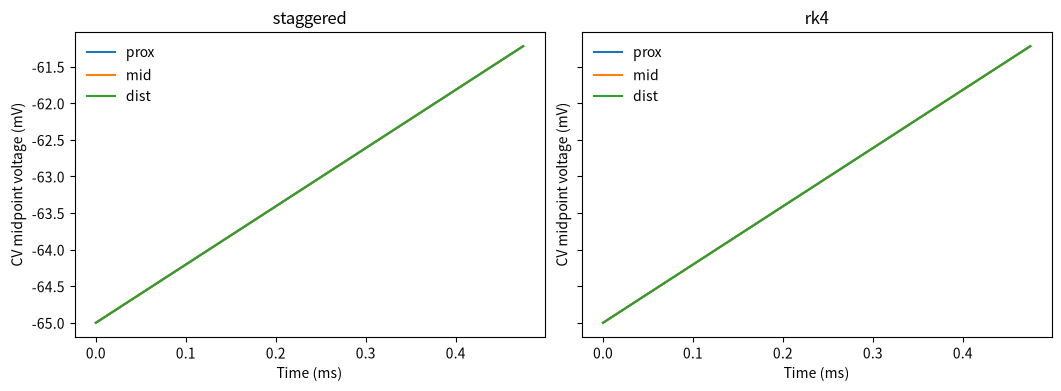

In [5]:
POSITIONS = {"prox": 0.0, "mid": 0.5, "dist": 1.0}


def location_clamp_cell(branch_x, solver):
    cell = braincell.Cell(
        make_soma(),
        pop_size=(1,),
        cv_policy=braincell.CVPerBranch(),
        V_init=-65.0 * u.mV,
        solver=solver,
    )
    cell.place(
        RootLocation(branch_x),
        braincell.mech.CurrentClamp(durations=0.5 * u.ms, amplitudes=0.1 * u.nA),
    )
    cell.record("v", braincell.observe.state("V"))
    return cell


placement_rows = []
placement_traces = {}
for solver in ("staggered", "rk4"):
    for position, branch_x in POSITIONS.items():
        cell = location_clamp_cell(branch_x, solver)
        placement = cell.point_placements[0]
        result = cell.run(dt=DT, duration=0.5 * u.ms)
        placement_rows.append((solver, position, placement.cv_position, placement.point_id, placement.cv_id))
        placement_traces[solver, position] = (
            result.samples["v"].time.to_decimal(u.ms),
            result.samples["v"].values.to_decimal(u.mV)[:, 0],
        )

print(f"{'solver':>10}  {'site':>6}  {'CV role':>8}  {'point':>7}  {'CV':>4}")
for solver, position, role, point_id, cv_id in placement_rows:
    print(f"{solver:>10}  {position:>6}  {role:>8}  {point_id:7d}  {cv_id:4d}")

figure, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True, constrained_layout=True)
for axis, solver in zip(axes, ("staggered", "rk4")):
    for position in POSITIONS:
        time_ms, voltage_mv = placement_traces[solver, position]
        axis.plot(time_ms, voltage_mv, label=position)
    axis.set(title=solver, xlabel="Time (ms)", ylabel="CV midpoint voltage (mV)")
    axis.legend(frameon=False)
plt.show()

## Performance audit

`Cell.point` uses its default `ralston2` and the one-CV cable `Cell` keeps `rk4`. Each run lasts 50 ms (2000 steps): every `Cell.run` call has an additional fixed overhead of about 1–2 ms (post-processing of recordings and so on), which hides the per-step cost in short runs. This section compares build, initialization, warm-up, reset and pure run times, and counts the differential, auxiliary and runtime parameter states separately. Every pure run sample starts after `reset_state()` has finished and synchronized; three warm-ups absorb tracing/compilation, and the steady values in the table are the median of five synchronized calls. The results describe only the current machine and backend; they are not a release benchmark.


Timing (run excludes reset):
     N         model      build       init    warm-up      reset        run    us/step
     1    Cell.point       4.72      40.55     233.08     10.599      0.787      0.393
     1   one-CV Cell       3.80      26.49     680.64     13.993      1.721      0.860
     8    Cell.point       3.02     740.37     401.91     39.293      2.458      1.229
     8   one-CV Cell       5.47     848.36     856.99     33.815      6.539      3.270
    32    Cell.point       2.80     868.92     409.41     38.151      2.745      1.372
    32   one-CV Cell       3.08     777.04    1160.65     78.115     14.907      7.453
   128    Cell.point       4.87    1018.67     522.12     26.259      6.100      3.050
   128   one-CV Cell       4.66    1074.95    1178.63     16.310     17.202      8.601
   512    Cell.point       3.28    1296.29     498.67     15.511     15.723      7.861
   512   one-CV Cell       6.06    1082.27    1669.67     33.927     63.967     31.984
  1000    Cell

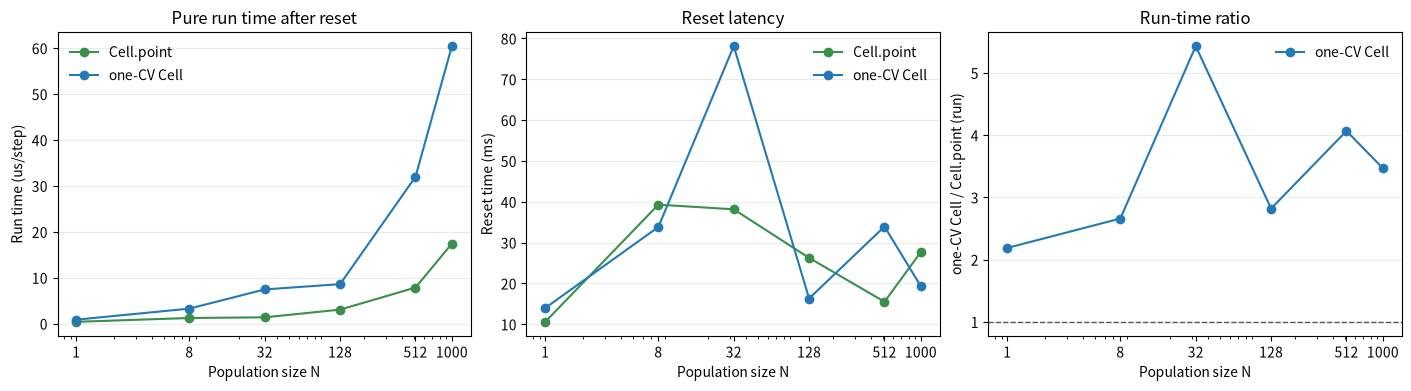

In [6]:
def state_elements(model):
    counts = {"differential": 0, "auxiliary": 0, "runtime_parameter": 0}
    for state in brainstate.graph.states(model).values():
        name = type(state).__name__
        category = (
            "differential"
            if name.startswith("DiffEq")
            else "runtime_parameter"
            if name == "RuntimeParameterState"
            else "auxiliary"
        )
        counts[category] += int(np.size(u.get_mantissa(state.value)))
    counts["total"] = sum(counts.values())
    return counts


def synchronize(model):
    jax.block_until_ready(tuple(state.value for state in brainstate.graph.states(model).values()))


def elapsed(call):
    started = time.perf_counter()
    output = call()
    jax.block_until_ready(output)
    return time.perf_counter() - started


def benchmark(size, duration=50.0 * u.ms, warmups=3, repeats=5):
    n_steps = int(round(float(duration / DT)))
    started = time.perf_counter()
    cell = build_one_cv_cell(
        size,
        active=True,
        clamp=braincell.mech.CurrentClamp(durations=duration, amplitudes=TOTAL_CURRENT),
    )
    cell_build = time.perf_counter() - started
    started = time.perf_counter()
    cell.init_state()
    cell_init = time.perf_counter() - started

    started = time.perf_counter()
    point = build_point_cell(
        size,
        active=True,
        solver="ralston2",
        clamp=braincell.mech.CurrentClamp(durations=duration, amplitudes=TOTAL_CURRENT),
    )
    point_build = time.perf_counter() - started
    started = time.perf_counter()
    point.init_state()
    point_init = time.perf_counter() - started

    rows = []
    for label, model, runner, build_s, init_s in (
        # RunResult is not a JAX pytree: wait on the recorded values, not on the result.
        ("Cell.point", point, lambda: point.run(dt=DT, duration=duration).samples["v"].values, point_build, point_init),
        ("one-CV Cell", cell, lambda: cell.run(dt=DT, duration=duration).samples["v"].values, cell_build, cell_init),
    ):

        def reset():
            model.reset_state()
            synchronize(model)

        def run_after_reset():
            reset()
            return elapsed(runner)

        warmup_s = [run_after_reset() for _ in range(warmups)]
        reset_s = [elapsed(reset) for _ in range(repeats)]
        run_s = [run_after_reset() for _ in range(repeats)]
        run_median = float(np.median(run_s))
        rows.append(
            {
                "size": size,
                "model": label,
                "build_ms": 1e3 * build_s,
                "init_ms": 1e3 * init_s,
                "warmup_ms": 1e3 * sum(warmup_s),
                "reset_ms": 1e3 * float(np.median(reset_s)),
                "run_ms": 1e3 * run_median,
                "us_per_step": 1e6 * run_median / n_steps,
                **state_elements(model),
            }
        )
    return rows


SIZES = (1, 8, 32, 128, 512, 1000)
benchmark_rows = [row for size in SIZES for row in benchmark(size)]

print("Timing (run excludes reset):")
print(f"{'N':>6}  {'model':>12}  {'build':>9}  {'init':>9}  {'warm-up':>9}  {'reset':>9}  {'run':>9}  {'us/step':>9}")
for row in benchmark_rows:
    print(
        f"{row['size']:6d}  {row['model']:>12}  {row['build_ms']:9.2f}  "
        f"{row['init_ms']:9.2f}  {row['warmup_ms']:9.2f}  {row['reset_ms']:9.3f}  "
        f"{row['run_ms']:9.3f}  {row['us_per_step']:9.3f}"
    )

print("\nState element counts:")
print(f"{'N':>6}  {'model':>12}  {'differential':>14}  {'auxiliary':>10}  {'runtime':>10}  {'total':>8}")
for row in benchmark_rows:
    print(
        f"{row['size']:6d}  {row['model']:>12}  {row['differential']:14d}  "
        f"{row['auxiliary']:10d}  {row['runtime_parameter']:10d}  {row['total']:8d}"
    )

by_model = {
    model: [row for row in benchmark_rows if row["model"] == model]
    for model in ("Cell.point", "one-CV Cell")
}
colors = {"Cell.point": "#3a8f4b", "one-CV Cell": "#2478b5"}
figure, axes = plt.subplots(1, 3, figsize=(14.0, 3.8), constrained_layout=True)
for model, rows in by_model.items():
    axes[0].plot(SIZES, [row["us_per_step"] for row in rows], marker="o", label=model, color=colors[model])
    axes[1].plot(SIZES, [row["reset_ms"] for row in rows], marker="o", label=model, color=colors[model])
ratios = [
    cable["us_per_step"] / point["us_per_step"]
    for point, cable in zip(by_model["Cell.point"], by_model["one-CV Cell"])
]
axes[2].plot(SIZES, ratios, marker="o", label="one-CV Cell", color=colors["one-CV Cell"])
axes[2].axhline(1.0, color="#555555", linewidth=1.0, linestyle="--")
for axis in axes:
    axis.set_xscale("log")
    axis.set_xticks(SIZES)
    axis.set_xticklabels(SIZES)
    axis.set_xlabel("Population size N")
    axis.grid(axis="y", alpha=0.25)
    axis.legend(frameon=False)
axes[0].set(ylabel="Run time (us/step)", title="Pure run time after reset")
axes[1].set(ylabel="Reset time (ms)", title="Reset latency")
axes[2].set(ylabel="one-CV Cell / Cell.point (run)", title="Run-time ratio")
plt.show()

## Conclusion

Use `Cell.point` for point neurons: `V` has shape `(N,)`, it is declared the same way as a morphological `Cell`, and when the model later switches to `Cell(Morphology.from_swc(...))`, `paint`, `place` and `record` need no rewriting.

`Network`, point synapses, Views and trainable parameters all work on a lumped `Cell`, with results that match the one-CV cable `Cell`. The one-CV cable `Cell` (shape `(N, 1)`) is needed only for proximal/distal endpoint semantics (the point placement of the previous section).
